# Site magnetization vs time

Load the time-evolution magnetization data and plot $\langle S^z_i \rangle$ as a function of time for each site. Run this notebook from the repository root, or update `magz_path` below.

In [78]:
using DelimitedFiles
using Plots

magz_path = joinpath("results", "time_evolution", "mag_z.csv")
data = readdlm(magz_path, ',', skipstart=1)

times = Float64.(data[:, 2])
sites = Int.(data[:, 3])
mag_z = Float64.(data[:, 4])

102400-element Vector{Float64}:
 -0.009420712150099158
  0.006095566472159714
 -0.01149192551716428
  0.008448976892652726
 -0.013167367704561735
  0.010255614438906473
 -0.01474446803669014
  0.011900533028107027
 -0.01636122655982244
  0.013545292513486894
  ⋮
 -0.04744856659845312
 -0.028444836037109112
 -0.012150905443624021
 -0.01983821112020077
  0.007955856415488143
 -0.014181141946194454
  0.014290332497549699
 -0.009493423922653468
  0.013655515260517614

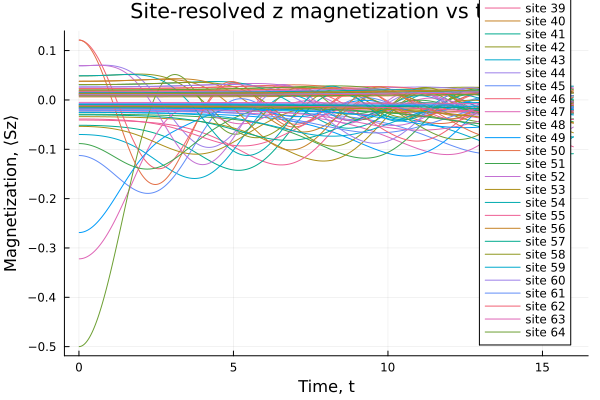

In [79]:
p = plot(
    xlabel="Time, t",
    ylabel="Magnetization, ⟨Sz⟩",
    title="Site-resolved z magnetization vs time",
    legend=:best,
)

for site in sort(unique(sites))
    indices = findall(==(site), sites)
    order = sortperm(times[indices])
    plot!(p, times[indices][order], mag_z[indices][order]; label="site $site")
end

display(p)

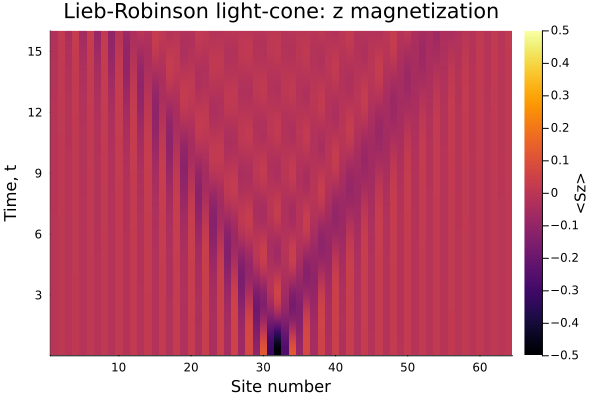

In [80]:
time_values = sort(unique(times))
site_values = sort(unique(sites))
mag_z_grid = fill(NaN, length(time_values), length(site_values))

for row in eachindex(mag_z)
    time_index = searchsortedfirst(time_values, times[row])
    site_index = searchsortedfirst(site_values, sites[row])
    mag_z_grid[time_index, site_index] = mag_z[row]
end

heatmap(
    site_values,
    time_values,
    mag_z_grid;
    xlabel="Site number",
    ylabel="Time, t",
    title="Lieb-Robinson light-cone: z magnetization",
    colorbar_title="<Sz>",
    clims=(-0.5, 0.5),
    interpolate=false,
)

Source site inferred from the first snapshot: 32
Fit window: t = 1.0 to 8.0
Front threshold: 5.0% of the largest magnetization change at each time
Left-front speed:  1.7012361548738144 sites per unit time (R² = 0.9674382082872194)
Right-front speed: 1.4900917753984801 sites per unit time (R² = 0.9837178875520507)
Mean measured speed: 1.5956639651361473 sites per unit time


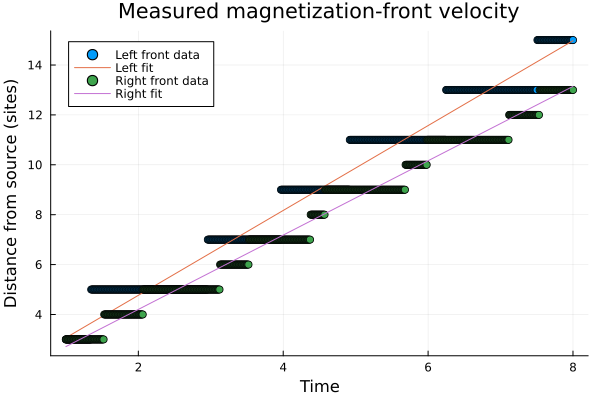

In [81]:
# Estimate the propagation speed directly from the measured magnetization front.
# The front is where |Sz(site, t) - Sz(site, first recorded time)| exceeds this
# fraction of the largest change at that time. Both settings can be adjusted.
threshold_fraction = 0.05
fit_time_min = 1.0
fit_time_max = min(8.0, maximum(time_values))

baseline = mag_z_grid[1, :]
source_index = argmax(abs.(baseline))
source_site = site_values[source_index]
front_left = fill(NaN, length(time_values))
front_right = fill(NaN, length(time_values))

for time_index in eachindex(time_values)
    change = abs.(mag_z_grid[time_index, :] .- baseline)
    peak_change = maximum(change)
    peak_change > 0 || continue
    threshold = threshold_fraction * peak_change

    left_sites = site_values[(site_values .< source_site) .& (change .>= threshold)]
    right_sites = site_values[(site_values .> source_site) .& (change .>= threshold)]
    isempty(left_sites) || (front_left[time_index] = source_site - minimum(left_sites))
    isempty(right_sites) || (front_right[time_index] = maximum(right_sites) - source_site)
end

function fit_front_velocity(front_distance, times, fit_start, fit_end)
    selected = (times .>= fit_start) .& (times .<= fit_end) .& isfinite.(front_distance)
    count(selected) >= 2 || error("Not enough front detections in the selected fit window.")

    fit_times = Float64.(times[selected])
    distances = Float64.(front_distance[selected])
    mean_time = sum(fit_times) / length(fit_times)
    mean_distance = sum(distances) / length(distances)
    slope = sum((fit_times .- mean_time) .* (distances .- mean_distance)) / sum((fit_times .- mean_time).^2)
    intercept = mean_distance - slope * mean_time
    fitted = intercept .+ slope .* fit_times
    r_squared = 1 - sum((distances .- fitted).^2) / sum((distances .- mean_distance).^2)
    return slope, r_squared, fit_times, distances, intercept
end

left_velocity, left_r2, left_times, left_distances, left_intercept =
    fit_front_velocity(front_left, time_values, fit_time_min, fit_time_max)
right_velocity, right_r2, right_times, right_distances, right_intercept =
    fit_front_velocity(front_right, time_values, fit_time_min, fit_time_max)
mean_velocity = (left_velocity + right_velocity) / 2

println("Source site inferred from the first snapshot: $source_site")
println("Fit window: t = $fit_time_min to $fit_time_max")
println("Front threshold: $(100 * threshold_fraction)% of the largest magnetization change at each time")
println("Left-front speed:  $left_velocity sites per unit time (R² = $left_r2)")
println("Right-front speed: $right_velocity sites per unit time (R² = $right_r2)")
println("Mean measured speed: $mean_velocity sites per unit time")

plot(left_times, left_distances; seriestype=:scatter, label="Left front data", xlabel="Time", ylabel="Distance from source (sites)", title="Measured magnetization-front velocity")
plot!(left_times, left_intercept .+ left_velocity .* left_times; label="Left fit")
scatter!(right_times, right_distances; label="Right front data")
plot!(right_times, right_intercept .+ right_velocity .* right_times; label="Right fit")

In [82]:
figure_dir = joinpath("results", "figures")
mkpath(figure_dir)

savefig(p, joinpath(figure_dir, "magnetization_sites.png"))

lightcone_plot = heatmap(
    site_values,
    time_values,
    mag_z_grid;
    xlabel="Site number",
    ylabel="Time, t",
    title="Lieb-Robinson light-cone: z magnetization",
    colorbar_title="<Sz>",
    clims=(-0.5, 0.5),
    interpolate=false,
)
savefig(lightcone_plot, joinpath(figure_dir, "magnetization_lightcone.png"))

velocity_plot = plot(
    left_times,
    left_distances;
    seriestype=:scatter,
    label="Left front data",
    xlabel="Time",
    ylabel="Distance from source (sites)",
    title="Measured magnetization-front velocity",
)
plot!(velocity_plot, left_times, left_intercept .+ left_velocity .* left_times; label="Left fit")
scatter!(velocity_plot, right_times, right_distances; label="Right front data")
plot!(velocity_plot, right_times, right_intercept .+ right_velocity .* right_times; label="Right fit")
savefig(velocity_plot, joinpath(figure_dir, "magnetization_front_velocity.png"))
println("Saved magnetization figures to $figure_dir")

Saved magnetization figures to results/figures
